In [1]:
%pwd

'd:\\Tipto\\hisab-lens\\notebooks'

In [2]:
import os
os.chdir("../")

In [3]:
from pathlib import Path
import pandas as pd

batch_11_df = pd.read_csv("data/high_quality_invoice/batch1_1.csv")
batch_11_df.head()

,File Name,Json Data,OCRed Text
0,batch1-0494.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Clark...",Invoice no: 84652373 Date of issue: 02/23/2021...
1,batch1-0489.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Willi...",Invoice no: 37451664 Date of issue: 06/11/2020...
2,batch1-0499.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Heste...",Invoice no: 40108666 Date of issue: 02/07/2020...
3,batch1-0497.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Olson...",Invoice no: 73285932 Date of issue: 07/25/2017...
4,batch1-0081.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Wilso...",Invoice no: 15288019 Date of issue: 09/07/2014...


In [4]:
print(batch_11_df.loc[0, "Json Data"])


{
  "invoice": {
    "client_name": "Clark-Foster",
    "client_address": "77477 Troy Cliff Apt. 853\nWashingtonbury, MS 78346",
    "seller_name": "Nguyen-Roach",
    "seller_address": "247 David Highway\nLake John, WV 84178",
    "invoice_number": "84652373",
    "invoice_date": "02/23/2021",
    "due_date": ""
  },
  "items": [
    {
      "description": "Stemware Rack Display Kitchen\nWine Glass Holder Bottle\nCarbon Steel Free Punch",
      "quantity": "1.00",
      "total_price": "46.55"
    },
    {
      "description": "VTG (4) 7 Ounce Since 1852\nMilk Bottle Wine Carafe Juice\nGlass with Cork Lids",
      "quantity": "1.00",
      "total_price": "15.40"
    },
    {
      "description": "Vintage Crystal Red Wine\nGlasses NOS West Germany\n1983 6 10 ounce elegant stems",
      "quantity": "1.00",
      "total_price": "39.00"
    },
    {
      "description": "3 Ikea Stainless Steel 4-bottle\nWine Rack 300.557.60 - great\ncondition gift it!",
      "quantity": "4.00",
      "to

In [5]:
import json

bad_rows = []
for i, s in enumerate(batch_11_df["Json Data"]):
    try:
        json.loads(s)
    except Exception as e:
        bad_rows.append((i, str(e)[:80]))

print("Total rows:", len(batch_11_df))
print("Bad JSON rows:", len(bad_rows))
print(bad_rows[:5])

Total rows: 499
Bad JSON rows: 0
[]


In [6]:
from PIL import Image
samaple_image_path = "data/high_quality_invoice/batch1_1/batch1-0494.jpg"

image = Image.open(samaple_image_path)
image.show()

In [7]:
from pathlib import Path
base_dir_batch1 = Path("data/high_quality_invoice/batch1_1")

batch_11_df["image_path"] = batch_11_df["File Name"].apply(lambda name: str(base_dir_batch1 / name))

In [8]:
batch_11_df.head()

,File Name,Json Data,OCRed Text,image_path
0,batch1-0494.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Clark...",Invoice no: 84652373 Date of issue: 02/23/2021...,data\high_quality_invoice\batch1_1\batch1-0494...
1,batch1-0489.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Willi...",Invoice no: 37451664 Date of issue: 06/11/2020...,data\high_quality_invoice\batch1_1\batch1-0489...
2,batch1-0499.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Heste...",Invoice no: 40108666 Date of issue: 02/07/2020...,data\high_quality_invoice\batch1_1\batch1-0499...
3,batch1-0497.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Olson...",Invoice no: 73285932 Date of issue: 07/25/2017...,data\high_quality_invoice\batch1_1\batch1-0497...
4,batch1-0081.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Wilso...",Invoice no: 15288019 Date of issue: 09/07/2014...,data\high_quality_invoice\batch1_1\batch1-0081...


In [9]:
batch_11_df.drop(columns=["File Name", "OCRed Text"], inplace=True)

C:\Users\tipto\AppData\Local\Temp\ipykernel_16500\979795646.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  batch_11_df.drop(columns=["File Name", "OCRed Text"], inplace=True)


In [10]:
batch_11_df.head()

,Json Data,image_path
0,"\n{\n ""invoice"": {\n ""client_name"": ""Clark...",data\high_quality_invoice\batch1_1\batch1-0494...
1,"\n{\n ""invoice"": {\n ""client_name"": ""Willi...",data\high_quality_invoice\batch1_1\batch1-0489...
2,"\n{\n ""invoice"": {\n ""client_name"": ""Heste...",data\high_quality_invoice\batch1_1\batch1-0499...
3,"\n{\n ""invoice"": {\n ""client_name"": ""Olson...",data\high_quality_invoice\batch1_1\batch1-0497...
4,"\n{\n ""invoice"": {\n ""client_name"": ""Wilso...",data\high_quality_invoice\batch1_1\batch1-0081...


In [11]:
batch_11_df["image_exists"] = batch_11_df["image_path"].apply(
    lambda p: Path(p["path"] if isinstance(p, dict) else p).exists()
)
batch_11_df["image_exists"].value_counts()

image_exists
True    499
Name: count, dtype: int64

In [12]:
batch_12_df = pd.read_csv("data/high_quality_invoice/batch1_2.csv")
batch_12_df.head()

,File Name,Json Data,OCRed Text
0,batch1-0500.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Ellis...",Invoice no: 34476404 Date of issue: 07/24/2018...
1,batch1-0501.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Thomp...",Invoice no: 18999056 Date of issue: 07/29/2011...
2,batch1-0502.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Hayne...",Invoice no: 33289699 Date of issue: 12/24/2012...
3,batch1-0503.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Peter...",Invoice no: 22758345 Date of issue: 12/21/2015...
4,batch1-0504.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Bradl...",Invoice no: 79036267 Date of issue: 09/16/2016...


In [13]:
import json

bad_rows = []
for i, s in enumerate(batch_12_df["Json Data"]):
    try:
        json.loads(s)
    except Exception as e:
        bad_rows.append((i, str(e)[:80]))

print("Total rows:", len(batch_12_df))
print("Bad JSON rows:", len(bad_rows))
print(bad_rows[:5])

Total rows: 426
Bad JSON rows: 0
[]


In [14]:
from pathlib import Path
base_dir_batch2 = Path("data/high_quality_invoice/batch1_2")

batch_12_df["image_path"] = batch_12_df["File Name"].apply(lambda name: str(base_dir_batch2 / name))

In [15]:
batch_12_df.drop(columns=["File Name", "OCRed Text"], inplace=True)

C:\Users\tipto\AppData\Local\Temp\ipykernel_16500\1290493622.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  batch_12_df.drop(columns=["File Name", "OCRed Text"], inplace=True)


In [16]:
batch_12_df["image_exists"] = batch_12_df["image_path"].apply(
    lambda p: Path(p["path"] if isinstance(p, dict) else p).exists()
)
batch_12_df["image_exists"].value_counts()

image_exists
True    426
Name: count, dtype: int64

In [17]:
batch_13_df = pd.read_csv("data/high_quality_invoice/batch1_3.csv")
batch_13_df.head()

,File Name,Json Data,OCRed Text
0,batch1-1142.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Mille...",Invoice no: 96556696 Date of issue: 02/25/2016...
1,batch1-1147.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Cruz,...",Invoice no: 95894022 Date of issue: 07/17/2014...
2,batch1-1080.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Carey...",Invoice no: 17585415 Date of issue: 09/26/2016...
3,batch1-1146.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Moore...",Invoice no: 27702906 Date of issue: 08/06/2015...
4,batch1-1090.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Thoma...",Invoice no: 34310027 Date of issue: 09/06/2016...


In [18]:
import json

bad_rows = []
for i, s in enumerate(batch_13_df["Json Data"]):
    try:
        json.loads(s)
    except Exception as e:
        bad_rows.append((i, str(e)[:80]))

print("Total rows:", len(batch_13_df))
print("Bad JSON rows:", len(bad_rows))
print(bad_rows[:5])

Total rows: 489
Bad JSON rows: 0
[]


In [19]:
base_dir_batch3 = Path("data/high_quality_invoice/batch1_3")

batch_13_df["image_path"] = batch_13_df["File Name"].apply(lambda name: str(base_dir_batch3 / name))

In [20]:
batch_13_df.drop(columns=["File Name", "OCRed Text"], inplace=True)

C:\Users\tipto\AppData\Local\Temp\ipykernel_16500\3692134158.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  batch_13_df.drop(columns=["File Name", "OCRed Text"], inplace=True)


In [21]:
batch_13_df["image_exists"] = batch_13_df["image_path"].apply(
    lambda p: Path(p["path"] if isinstance(p, dict) else p).exists()
)
batch_11_df["image_exists"].value_counts()

image_exists
True    499
Name: count, dtype: int64

In [22]:
batch_13_df.head()

,Json Data,image_path,image_exists
0,"\n{\n ""invoice"": {\n ""client_name"": ""Mille...",data\high_quality_invoice\batch1_3\batch1-1142...,True
1,"\n{\n ""invoice"": {\n ""client_name"": ""Cruz,...",data\high_quality_invoice\batch1_3\batch1-1147...,True
2,"\n{\n ""invoice"": {\n ""client_name"": ""Carey...",data\high_quality_invoice\batch1_3\batch1-1080...,True
3,"\n{\n ""invoice"": {\n ""client_name"": ""Moore...",data\high_quality_invoice\batch1_3\batch1-1146...,True
4,"\n{\n ""invoice"": {\n ""client_name"": ""Thoma...",data\high_quality_invoice\batch1_3\batch1-1090...,True


In [23]:
batch_11_df.columns, batch_12_df.columns, batch_13_df.columns

(Index(['Json Data', 'image_path', 'image_exists'], dtype='str'),
 Index(['Json Data', 'image_path', 'image_exists'], dtype='str'),
 Index(['Json Data', 'image_path', 'image_exists'], dtype='str'))

In [24]:
combined_df = pd.concat([batch_11_df, batch_12_df, batch_13_df], ignore_index=True)
combined_df.shape

(1414, 3)

In [25]:
combined_df = combined_df.sample(frac = 1)

In [26]:
combined_df = combined_df.drop(columns = ["image_exists"])

In [27]:
combined_df.head()

,Json Data,image_path
830,"\n{\n ""invoice"": {\n ""client_name"": ""Henry...",data\high_quality_invoice\batch1_2\batch1-0888...
798,"\n{\n ""invoice"": {\n ""client_name"": ""Tate,...",data\high_quality_invoice\batch1_2\batch1-0899...
1353,"\n{\n ""invoice"": {\n ""client_name"": ""Jacks...",data\high_quality_invoice\batch1_3\batch1-1438...
91,"\n{\n ""invoice"": {\n ""client_name"": ""Meza,...",data\high_quality_invoice\batch1_1\batch1-0383...
765,"\n{\n ""invoice"": {\n ""client_name"": ""Mata,...",data\high_quality_invoice\batch1_2\batch1-0841...


In [28]:
combined_df.info()

<class 'pandas.DataFrame'>
Index: 1414 entries, 830 to 1140
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Json Data   1414 non-null   str  
 1   image_path  1414 non-null   str  
dtypes: str(2)
memory usage: 1.7 MB


In [29]:
combined_df.loc[0, "image_path"]

'data\\high_quality_invoice\\batch1_1\\batch1-0494.jpg'

In [30]:
combined_df = combined_df.reset_index(drop=True)
combined_df = combined_df.rename(
    columns = {
        "Json Data": "json_data",
        "image_path": "image_path"
    }
)
combined_df["image_path"] = combined_df["image_path"].str.replace("\\", "/", regex=False)

In [31]:
combined_df.loc[0]["image_path"]

'data/high_quality_invoice/batch1_2/batch1-0888.jpg'

In [32]:
combined_df.loc[0]["json_data"]

'\n{\n  "invoice": {\n    "client_name": "Henry Ltd",\n    "client_address": "06376 James Burg\\nLewisland, SC 66050",\n    "seller_name": "Long, Mcclain and Harmon",\n    "seller_address": "431 Marquez Ramp Suite 716\\nWest Joshua, TX 45363",\n    "invoice_number": "38166771",\n    "invoice_date": "08/09/2018",\n    "due_date": ""\n  },\n  "items": [\n    {\n      "description": "TWO NEW CORK CAGE ORNAMENTS: Wine Barrel & Wine Bottle Bar Tree Decorations!",\n      "quantity": "4.00",\n      "total_price": "51.70"\n    }\n  ],\n  "subtotal": {\n    "tax": "4.70",\n    "discount": "",\n    "total": "51.70"\n  },\n  "payment_instructions": {\n    "due_date": "",\n    "bank_name": "",\n    "account_number": "",\n    "payment_method": ""\n  }\n}\n'

In [33]:
combined_df.loc[10]

json_data     \n{\n  "invoice": {\n    "client_name": "River...
image_path    data/high_quality_invoice/batch1_2/batch1-0727...
Name: 10, dtype: str

In [34]:
import json 
from datasets import Dataset, DatasetDict, Features, Value, Image

features = Features({
    "id": Value("string"),
    "image": Image(),
    "json_data": Value("string")
})

In [35]:
ds_df = combined_df.rename(
    columns = {
        "image_path": "image"
    }
)[["image", "json_data"]]
ds_df

,image,json_data
0,data/high_quality_invoice/batch1_2/batch1-0888...,"\n{\n ""invoice"": {\n ""client_name"": ""Henry..."
1,data/high_quality_invoice/batch1_2/batch1-0899...,"\n{\n ""invoice"": {\n ""client_name"": ""Tate,..."
2,data/high_quality_invoice/batch1_3/batch1-1438...,"\n{\n ""invoice"": {\n ""client_name"": ""Jacks..."
3,data/high_quality_invoice/batch1_1/batch1-0383...,"\n{\n ""invoice"": {\n ""client_name"": ""Meza,..."
4,data/high_quality_invoice/batch1_2/batch1-0841...,"\n{\n ""invoice"": {\n ""client_name"": ""Mata,..."
...,...,...
1409,data/high_quality_invoice/batch1_1/batch1-0128...,"\n{\n ""invoice"": {\n ""client_name"": ""Rodri..."
1410,data/high_quality_invoice/batch1_3/batch1-1435...,"\n{\n ""invoice"": {\n ""client_name"": ""David..."
1411,data/high_quality_invoice/batch1_3/batch1-1263...,"\n{\n ""invoice"": {\n ""client_name"": ""Clark..."
1412,data/high_quality_invoice/batch1_1/batch1-0183...,"\n{\n ""invoice"": {\n ""client_name"": ""Baile..."


In [36]:
dataset = Dataset.from_pandas(ds_df, preserve_index=False)
dataset

Dataset({
    features: ['image', 'json_data'],
    num_rows: 1414
})

In [37]:
dataset["image"][0]

'data/high_quality_invoice/batch1_2/batch1-0888.jpg'

In [38]:
# convert the dataset image path to image object
dataset = dataset.cast_column("image", Image())

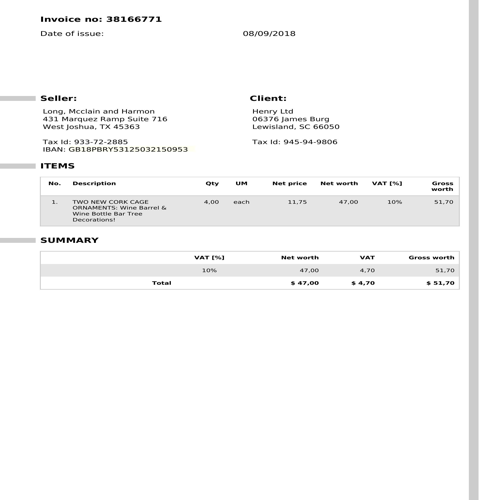

In [39]:
dataset[0]["image"].resize((500, 500))

In [40]:
print(dataset[0]["json_data"])


{
  "invoice": {
    "client_name": "Henry Ltd",
    "client_address": "06376 James Burg\nLewisland, SC 66050",
    "seller_name": "Long, Mcclain and Harmon",
    "seller_address": "431 Marquez Ramp Suite 716\nWest Joshua, TX 45363",
    "invoice_number": "38166771",
    "invoice_date": "08/09/2018",
    "due_date": ""
  },
  "items": [
    {
      "description": "TWO NEW CORK CAGE ORNAMENTS: Wine Barrel & Wine Bottle Bar Tree Decorations!",
      "quantity": "4.00",
      "total_price": "51.70"
    }
  ],
  "subtotal": {
    "tax": "4.70",
    "discount": "",
    "total": "51.70"
  },
  "payment_instructions": {
    "due_date": "",
    "bank_name": "",
    "account_number": "",
    "payment_method": ""
  }
}




{
  "invoice": {
    "client_name": "Hensley LLC",
    "client_address": "875 Jessica Course Apt. 269\nNorth Kari, LA 34931",
    "seller_name": "Pacheco, Simmons and Coleman",
    "seller_address": "241 Heidi Vista Apt. 333\nOdomville, DC 06454",
    "invoice_number": "65507091",
    "invoice_date": "07/30/2014",
    "due_date": ""
  },
  "items": [
    {
      "description": "Yilong 1'x1.5' 400Lines Area Rug High Density Hand knotted Silk Carpet 221H",
      "quantity": "1,00",
      "total_price": "594,00"
    },
    {
      "description": "YILONG 6'x9' Handmade Silk Area Rug Chinese Art Deco Classic Indoor Carpet",
      "quantity": "5,00",
      "total_price": "66 000,00"
    },
    {
      "description": "Faux Fur Animal Print Hide Skin Rug Cowhide Area Rug Floor Mat Carpet 33.5\"X43\"",
      "quantity": "4,00",
      "total_price": "114,53"
    },
    {
      "description": "Moroccan Amazigh Handmade Carpet 14'2\" x 7'5\"",
      "quantity": "2,00",
      "total_price": "752,4

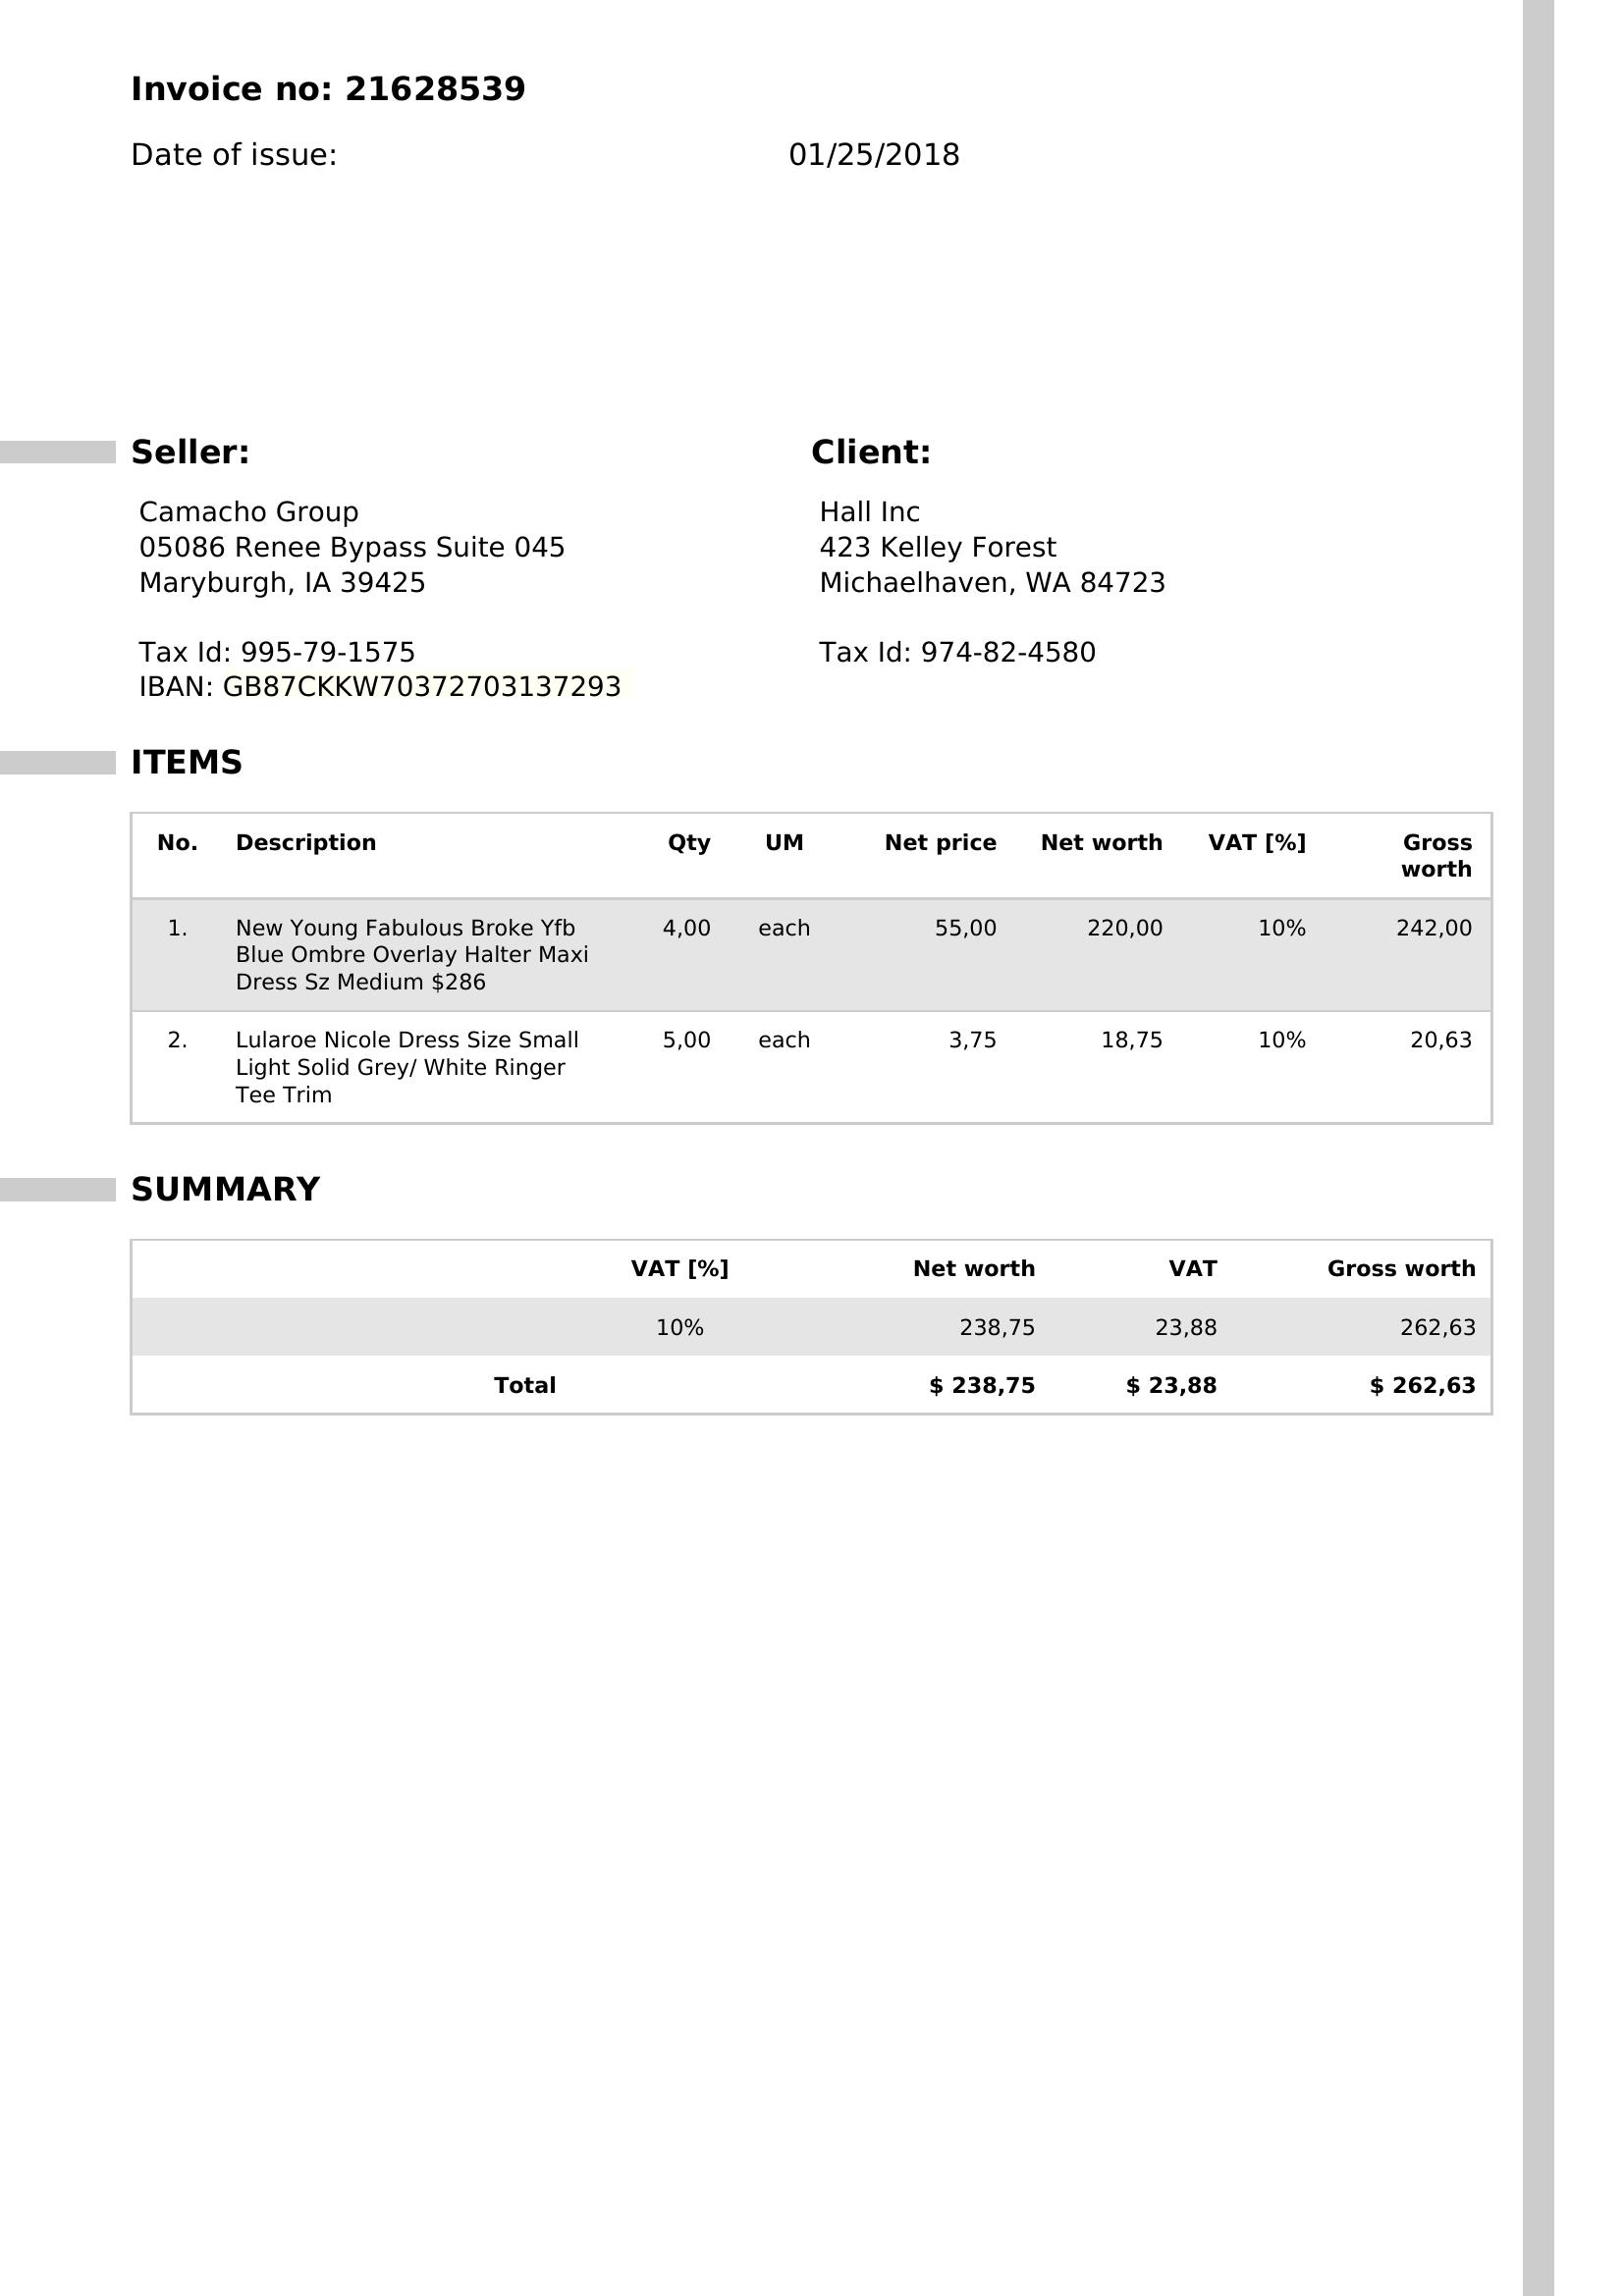

In [41]:
import random
sample = dataset[random.randint(0 , len(dataset) - 1)]
print(sample["json_data"])
dataset[random.randint(0 , len(dataset) - 1)]["image"]

In [42]:
dataset

Dataset({
    features: ['image', 'json_data'],
    num_rows: 1414
})

In [43]:
dataset.num_rows

1414

In [44]:
from datasets import DatasetDict

split1 = dataset.train_test_split(test_size = 0.3, seed = 42)
split2 = split1["test"].train_test_split(test_size = 0.5, seed = 42)

In [45]:
dataset_final = DatasetDict({
    "train": split1["train"],
    "val": split2["train"],
    "test": split2["test"]
})

In [46]:
dataset_final

DatasetDict({
    train: Dataset({
        features: ['image', 'json_data'],
        num_rows: 989
    })
    val: Dataset({
        features: ['image', 'json_data'],
        num_rows: 212
    })
    test: Dataset({
        features: ['image', 'json_data'],
        num_rows: 213
    })
})

In [47]:
from dotenv import load_dotenv
load_dotenv()
HF_TOKEN = os.getenv("HF_TOKEN")

In [48]:
# push the datset to huggingface
from huggingface_hub import  login
login(
    token = HF_TOKEN
)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


In [49]:
# first save locally
output_dir = "data/hisab_lens_dataset"
dataset_final.save_to_disk(output_dir)

Saving the dataset (0/1 shards):   0%|          | 0/989 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/212 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/213 [00:00<?, ? examples/s]

In [50]:
dataset_final

DatasetDict({
    train: Dataset({
        features: ['image', 'json_data'],
        num_rows: 989
    })
    val: Dataset({
        features: ['image', 'json_data'],
        num_rows: 212
    })
    test: Dataset({
        features: ['image', 'json_data'],
        num_rows: 213
    })
})

In [51]:
# now push it to the hf
dataset_final.push_to_hub(
    repo_id="tiptoghosh/hisab-lens",
    private = False, # make the dataset public
    max_shard_size = "1GB"
)

Setting num_proc from 1 back to 1 for the train split to disable multiprocessing as it only contains one shard.


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Map:   0%|          | 0/989 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/3 [00:00<?, ?ba/s]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

... (12 outputs left out)

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            

CommitInfo(commit_url='https://huggingface.co/datasets/tiptoghosh/hisab-lens/commit/d1b1fe1e72593924759d3e0c6c3908bba5e87c2d', commit_message='Upload dataset', commit_description='', oid='d1b1fe1e72593924759d3e0c6c3908bba5e87c2d', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/tiptoghosh/hisab-lens', endpoint='https://huggingface.co', repo_type='dataset', repo_id='tiptoghosh/hisab-lens'), pr_revision=None, pr_num=None)